In [1]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, normalize
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import pdb

from google.colab import files
from google.colab import drive

!pip install openslide-python
!pip install openslide-bin
!pip install umap-learn
!pip install banditpam
!pip install scikit-learn-extra
!pip install cuml-cuda11x cupy-cuda11x



import openslide
from openslide import OpenSlide
import umap

ERROR: Could not find a version that satisfies the requirement cuml-cuda11x (from versions: none)
ERROR: No matching distribution found for cuml-cuda11x


In [2]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
features = np.load('/content/drive/MyDrive/Perso/SLA/Asclepios/wsi_features/0.features.0.npy')
pos = np.load('/content/drive/MyDrive/Perso/SLA/Asclepios/wsi_features/0.position.npy')
image_path = '/content/drive/MyDrive/Perso/SLA/Asclepios/svs_slides/image_test.svs'
slide = OpenSlide(image_path)

In [4]:
features.shape
features[0]

array([-2.8108242 , -0.1599479 ,  1.2133316 , ...,  0.65707105,
        0.7809171 ,  0.2795394 ], dtype=float32)

In [5]:
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)
embedding_normalized = normalize(features, norm='l2')
print(features_scaled[0], embedding_normalized)

[-2.6611238   0.93775797  0.0087793  ...  3.8987162   3.5014343
  3.0469594 ] [[-0.09429446 -0.00536576  0.04070352 ...  0.0220427   0.02619736
   0.00937768]
 [-0.08977592 -0.00630749  0.03822079 ...  0.01077143  0.01587824
   0.00634268]
 [-0.08305663 -0.00675724  0.03723595 ...  0.00682437  0.00674108
   0.00359925]
 ...
 [-0.08995968 -0.00620295  0.03617568 ...  0.01331738  0.01755544
   0.00812552]
 [-0.09025084 -0.00633699  0.03763499 ...  0.0082307   0.01259023
   0.00394064]
 [-0.09214694 -0.00578592  0.03802409 ...  0.01519103  0.02122997
   0.00796847]]


In [6]:
print(slide.dimensions)
print(features.shape)

pos_centers = pos[:, :2] + np.array([112, 112])
pos_centers = pos_centers.astype(float)
print(pos[0], pos_centers[0])
pos_centers /= np.array([slide.dimensions[0], slide.dimensions[0]])
print(pos[0])
print(pos_centers[0])

# ajout données spatiale
feats_spatial = np.concatenate((features, pos), axis=1)
embedding_normalized_spatial = normalize(feats_spatial, norm='l2')
print(feats_spatial.shape)

(47990, 32626)
(6162, 1536)
[32704   224 32928   448] [32816.   336.]
[32704   224 32928   448]
[0.68380913 0.00700146]
(6162, 1540)


In [7]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
import umap

def visualize_embeddings(embeddings, model='tse', title="Visualisation des embeddings avec t-SNE"):
    if model == 'tse':
        tsne = TSNE(n_components=2, perplexity=30, random_state=42)
        embeddings_2d = tsne.fit_transform(embeddings)
    elif model == 'pca':
        pca = PCA(n_components=2)
        embeddings_2d = pca.fit_transform(embeddings)
    elif model == 'umap':
        umap_reducer = umap.UMAP(n_components=2, random_state=42)
        embeddings_2d = umap_reducer.fit_transform(embeddings)
    else:
        raise ValueError("Modèle inconnu. Choisissez parmi 'tse', 'pca' ou 'umap'.")
    plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1])
    plt.title(title)
    plt.show()

# # Visualisation des embeddings normalisés
# visualize_embeddings(embedding_normalized, 'tse', title="t-SNE des embeddings normalisés")

# # Visualisation des embeddings normalisés spatiaux
# visualize_embeddings(embedding_normalized_spatial, model='tse', title="t-SNE des embeddings normalisés spatiaux")

# # Visualisation des embeddings normalisés
# visualize_embeddings(embedding_normalized, 'pca', title="PCA des embeddings normalisés")

# # Visualisation des embeddings normalisés spatiaux
# visualize_embeddings(embedding_normalized_spatial, model='pca', title="PCA des embeddings normalisés spatiaux")

# # Visualisation des embeddings normalisés
# visualize_embeddings(embedding_normalized, 'umap', title="UMAP des embeddings normalisés")

# # Visualisation des embeddings normalisés spatiaux
# visualize_embeddings(embedding_normalized_spatial, model='umap', title="UMAP des embeddings normalisés spatiaux")


In [8]:
!git clone https://github.com/rapidsai/rapidsai-csp-utils.git
!python rapidsai-csp-utils/colab/pip-install.py

fatal: destination path 'rapidsai-csp-utils' already exists and is not an empty directory.
Installing RAPIDS remaining 24.12.* libraries
Using Python 3.11.11 environment at /usr
Audited 11 packages in 87ms

        ***********************************************************************
        The pip install of RAPIDS is complete.

        Please do not run any further installation from the conda based installation methods, as they may cause issues!

        Please ensure that you're pulling from the git repo to remain updated with the latest working install scripts.

        Troubleshooting:
            - If there is an installation failure, please check back on RAPIDSAI owned templates/notebooks to see how to update your personal files.
            - If an installation failure persists when using the latest script, please make an issue on https://github.com/rapidsai-community/rapidsai-csp-utils
        ***********************************************************************
        


In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import pairwise_distances_argmin_min

# Try to import cuML and CuPy
try:
    import cuml
    import cupy as cp
    GPU_AVAILABLE = True
except ImportError:
    from sklearn.cluster import KMeans  # Import KMeans from scikit-learn if cuML is not available
    GPU_AVAILABLE = False

# Fonction pour détecter automatiquement le "coude"
def find_optimal_k(scores, method='elbow'):
    if method == 'elbow':
        diffs = np.diff(scores)
        second_diffs = np.diff(diffs)
        third_diffs = np.diff(second_diffs)
        optimal_k = np.argmax(third_diffs) + 2  # Ajouter 2 car les indices de diff sont décalés
    elif method in ["silhouette", "calinski_harabasz", "BanditPam"]:
        optimal_k = np.argmax(scores) + 2  # Ajouter 2 car l'index commence à 2
    elif method in ["davies_bouldin", "bic"]:
        optimal_k = np.argmin(scores) + 2  # Ajouter 2 car l'index commence à 2
    return optimal_k

def evaluate_clusters(X, k_range=range(2, 10), method="elbow", title="Évaluation des clusters"):
    """Évalue différentes métriques pour déterminer le nombre optimal de clusters."""
    scores = []

    # Use GPU if available, otherwise use CPU
    if GPU_AVAILABLE:
        X = cp.asarray(X)
    else:
        X = X # Use X directly if GPU is not available

    for k in k_range:
        if method == "elbow":  # Méthode du coude
            if GPU_AVAILABLE:
                model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X)
                scores.append(model.inertia_)
            else:
                model = KMeans(n_clusters=k, random_state=42).fit(X)
                scores.append(model.inertia_)
        elif method == "silhouette":  # Score de silhouette
            if GPU_AVAILABLE:
                model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X)
                labels = model.labels_
                scores.append(silhouette_score(X, labels))
            else:
                model = KMeans(n_clusters=k, random_state=42).fit(X)
                labels = model.labels_
                scores.append(silhouette_score(X, labels))
        elif method == "davies_bouldin":  # Indice de Davies-Bouldin
            if GPU_AVAILABLE:
                model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X)
                labels = model.labels_
                scores.append(silhouette_score(X, labels))
            else:
                model = KMeans(n_clusters=k, random_state=42).fit(X)
                labels = model.labels_
                scores.append(davies_bouldin_score(X, labels))
        elif method == "calinski_harabasz":  # Indice de Calinski-Harabasz
            if GPU_AVAILABLE:
                model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X)
                labels = model.labels_
                scores.append(silhouette_score(X, labels))
            else:
                model = KMeans(n_clusters=k, random_state=42).fit(X)
                labels = model.labels_
                scores.append(calinski_harabasz_score(X, labels))
        elif method == "BanditPam":
            model = KMedoids(n_clusters=k, random_state=0).fit(X.get())
            scores.append(-model.inertia_)
        else:
            raise ValueError("Méthode inconnue. Choisissez parmi : 'elbow', 'silhouette', 'davies_bouldin', 'calinski_harabasz', 'bic'.")

    # Détermination du k optimal en fonction de la métrique
    optimal_k = find_optimal_k(scores, method=method)  # Détection du "coude" (changement de pente)

    print(f"optimal_k: {optimal_k}")

    # Affichage du graphique
    plt.plot(k_range, scores, marker="o")
    plt.scatter(optimal_k, scores[k_range.index(optimal_k)], color='red', s=100, zorder=3)
    plt.axvline(optimal_k, color='r', linestyle='--', label='Vertical Line at optimal k')
    plt.xlabel("Nombre de clusters (k)")
    plt.ylabel(method.replace("_", " ").title())  # Formatage du label
    plt.title(title)
    plt.show()

    return optimal_k

def apply_clustering(X, k, method):
    if method == "BanditPam":
        model = KMedoids(n_clusters=k, random_state=0).fit(X)
    else:
        if GPU_AVAILABLE:
            model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X)
        else:
            model = KMeans(n_clusters=k, random_state=42).fit(X)
    return model

In [10]:
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
import umap

def display_embedding(embeddings, model, mode='tse', title="Visualisation des embeddings"):
    # Définir la carte de couleurs
    cmap = plt.get_cmap('viridis')

    # Obtenir les labels des clusters
    try:
        labels = model.labels_
    except:
        labels = model.labels_.get()

    # Obtenir le nombre de clusters
    n_clusters = len(np.unique(labels))

    # Générer une liste de couleurs pour chaque cluster
    colors = [cmap(i / n_clusters) for i in range(n_clusters)]

    # Mapper chaque label à sa couleur correspondante
    label_color_map = {label: colors[i] for i, label in enumerate(np.unique(labels))}
    print(len(label_color_map))
    # Convertir les embeddings en 2D
    if mode == 'tse':
        # Get the number of cluster centers
        n_cluster_centers = model.cluster_centers_.shape[0]

        # Adjust perplexity to be less than n_samples if needed
        perplexity = min(30, n_cluster_centers - 1)

        tsne = TSNE(n_components=2, perplexity=perplexity, random_state=42)
        embeddings_2d = tsne.fit_transform(embeddings)
        if GPU_AVAILABLE:
            cluster_centers_2d = tsne.fit_transform(cp.asnumpy(model.cluster_centers_))
        else:
            cluster_centers_2d = tsne.fit_transform(model.cluster_centers_)
    elif mode == 'pca':
        pca = PCA(n_components=2)
        embeddings_2d = pca.fit_transform(embeddings)
        if GPU_AVAILABLE:
            cluster_centers_2d = pca.fit_transform(cp.asnumpy(model.cluster_centers_))
        else:
            cluster_centers_2d = pca.fit_transform(model.cluster_centers_)
    elif mode == 'umap':
        umap_reducer = umap.UMAP(n_components=2, random_state=42)
        embeddings_2d = umap_reducer.fit_transform(embeddings)
        if GPU_AVAILABLE:
            cluster_centers_2d = umap_reducer.transform(cp.asnumpy(model.cluster_centers_))
        else:
            cluster_centers_2d = umap_reducer.transform(model.cluster_centers_)
    else:
        raise ValueError("Modèle inconnu. Choisissez parmi 'tse', 'pca' ou 'umap'.")

    # Tracer les points avec les couleurs des clusters
    point_colors = [label_color_map[label] for label in labels]
    plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1], c=point_colors, s=50, alpha=0.6, edgecolors='w', linewidth=0.5)

    # Tracer les centres des clusters avec les mêmes couleurs
    center_colors = [label_color_map[label] for label in np.unique(labels)]
    plt.scatter(cluster_centers_2d[:, 0], cluster_centers_2d[:, 1], c=center_colors, s=200, marker='X', edgecolors='k', linewidth=1.5)

    plt.title(title)
    plt.show()

optimal_k: 12


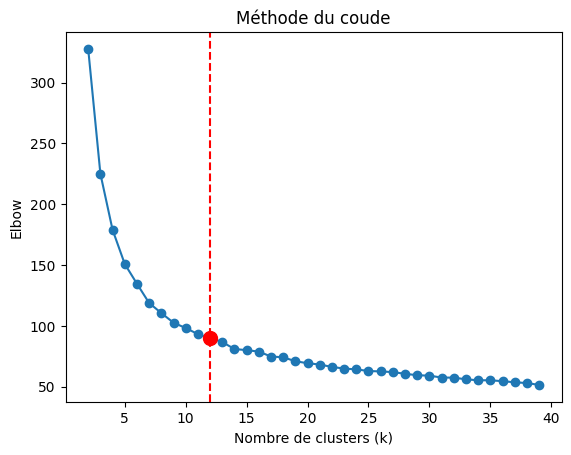

optimal_k: 36


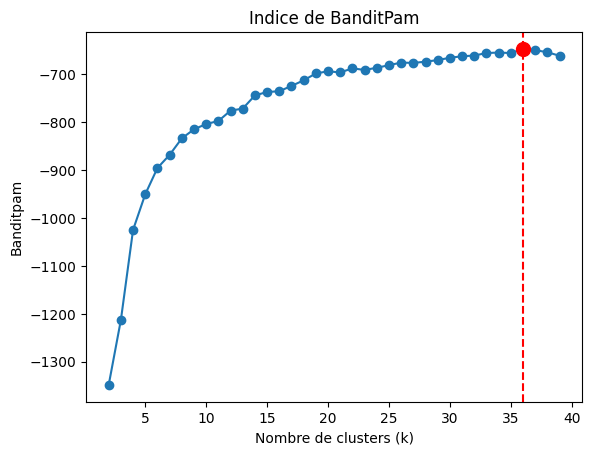

In [11]:
optimal_k_elbow = evaluate_clusters(embedding_normalized, k_range=range(2, 40, 1), method="elbow", title="Méthode du coude")
optimal_k_BanditPam = evaluate_clusters(embedding_normalized, k_range=range(2, 40, 1), method="BanditPam", title="Indice de BanditPam")

# optimal_k_elbow_s = evaluate_clusters(embedding_normalized_spatial, k_range=range(2, 40, 1), method="elbow", title="Méthode du coude")
# optimal_k_BanditPam_s = evaluate_clusters(embedding_normalized_spatial, k_range=range(2, 40, 1), method="BanditPam", title="Indice de BanditPam")

In [12]:
print(optimal_k_elbow)
print(optimal_k_BanditPam)

12
36


In [13]:
model_elbow = apply_clustering(embedding_normalized, optimal_k_elbow, '')
model_BanditPam = apply_clustering(embedding_normalized, optimal_k_BanditPam, 'BanditPam')
# model_elbow_s = apply_clustering(embedding_normalized_spatial, optimal_k_elbow_s, '')
# model_BanditPam_s = apply_clustering(embedding_normalized_spatial, optimal_k_BanditPam_s, 'BanditPam')

In [14]:
print(len(set(model_BanditPam.labels_)))
print(len(set(model_elbow.labels_)))

36
12


12


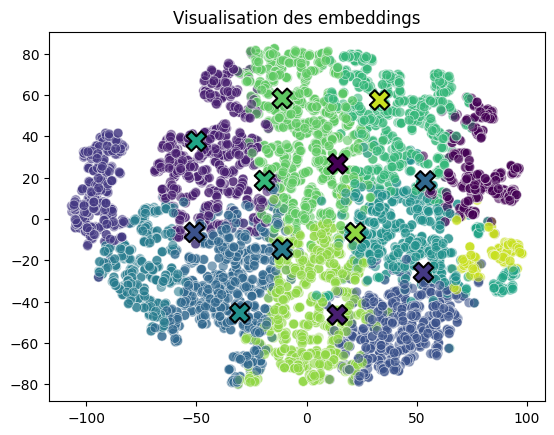

36


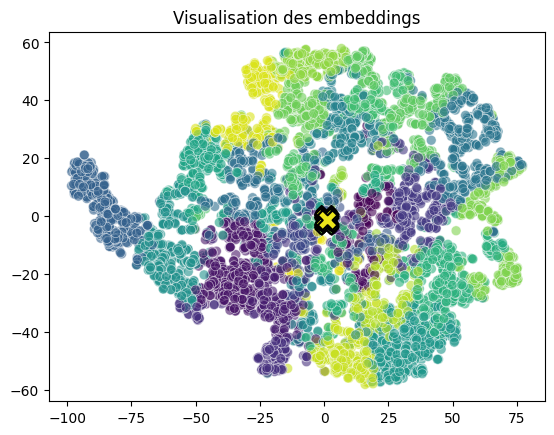

In [19]:
display_embedding(embedding_normalized, model_elbow, mode='tse')
display_embedding(embedding_normalized, model_BanditPam, mode='tse')

# display_embedding(embedding_normalized_spatial, model_elbow_s, mode='tse')
# display_embedding(embedding_normalized_spatial, model_BanditPam_s, mode='tse')

In [15]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
similarity_matrix = cosine_similarity(embedding_normalized)
similarity_matrix = scaler.fit_transform(similarity_matrix)

In [16]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def create_graph(coordinates_2d, labels, similarity_matrix, seuil):
    """
    Crée un graphe où les nœuds représentent des points 2D et les arêtes relient
    tous les nœuds appartenant à la même classe.

    :param coordinates_2d: numpy array de forme (n_samples, 2) contenant les coordonnées 2D des points.
    :param labels: liste ou array contenant les labels de classe pour chaque point.
    """
    graph = nx.Graph()

    # Ajouter les nœuds avec leurs positions 2D et leurs labels
    for i, (coord, label) in enumerate(zip(coordinates_2d, labels)):
        graph.add_node(i, pos=tuple([coord[0], -coord[1]]), label=label)

    # Ajouter les arêtes entre les nœuds similaires
        for i in range(len(labels)):
            for j in range(i + 1, len(labels)):  # Pour éviter les doublons et les boucles
                if similarity_matrix[i, j] > seuil:
                    graph.add_edge(i, j, weight=similarity_matrix[i, j])

    # Visualiser le graphe
    plt.figure(figsize=(20, 20))

    # Get node positions from graph data
    pos = nx.get_node_attributes(graph, 'pos')

    labels = nx.get_node_attributes(graph, 'label')
    unique_labels = set(labels.values())
    colors = plt.cm.rainbow(np.linspace(0, 1, len(unique_labels)))
    color_map = {label: color for label, color in zip(unique_labels, colors)}

    node_colors = [color_map[labels[node]] for node in graph.nodes()]
    nx.draw(graph, pos, node_color=node_colors, with_labels=False, node_size=50, edge_color='gray', alpha=0.5, width=0.5)
    plt.title("Graphe des similarités par classe sur les données 2D")
    plt.xlabel("Composante principale 1")
    plt.ylabel("Composante principale 2")
    plt.show()

In [17]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import cupy as cp
from collections import defaultdict


def create_graph_gpu(coordinates_2d, labels, similarity_matrix, seuil):
    """
    Crée un graphe en utilisant le GPU pour accélérer la création des arêtes
    basées sur la matrice de similarité.

    :param coordinates_2d: numpy array de forme (n_samples, 2) contenant les coordonnées 2D des points.
    :param labels: liste ou array contenant les labels de classe pour chaque point.
    :param similarity_matrix: numpy array de forme (n_samples, n_samples) contenant les similarités entre les points.
    :param seuil: seuil de similarité pour créer une arête.
    """
    graph = nx.Graph()

    # Ajouter les nœuds avec leurs positions 2D et leurs labels
    for i, (coord, label) in enumerate(zip(coordinates_2d, labels)):
        graph.add_node(i, pos=tuple([coord[0], -coord[1]]), label=label)

    # Convertir la matrice de similarité et le seuil en cupy arrays pour le GPU
    similarity_matrix_gpu = cp.asarray(similarity_matrix)
    seuil_gpu = cp.asarray(seuil)

    # Trouver les indices des paires de nœuds où la similarité est supérieure au seuil sur GPU
    indices_gpu = cp.where(similarity_matrix_gpu > seuil_gpu)

    # Récupérer les indices depuis le GPU vers le CPU

    # Visualiser le graphe (reste sur CPU)
    plt.figure(figsize=(20, 20))
    pos = nx.get_node_attributes(graph, 'pos')
    labels_nodes = nx.get_node_attributes(graph, 'label')
    unique_labels = set(labels_nodes.values())
    colors = plt.cm.rainbow(np.linspace(0, 1, len(unique_labels)))
    color_map = {label: color for label, color in zip(unique_labels, colors)}
    node_colors = [color_map[labels_nodes[node]] for node in graph.nodes()]
    nx.draw(graph, pos, node_color=node_colors, with_labels=False, node_size=50, edge_color='gray', alpha=0.5, width=0.5)
    plt.title("Graphe des similarités par classe sur les données 2D (GPU Optimisé)")
    plt.xlabel("Composante principale 1")
    plt.ylabel("Composante principale 2")
    plt.show()

    return graph

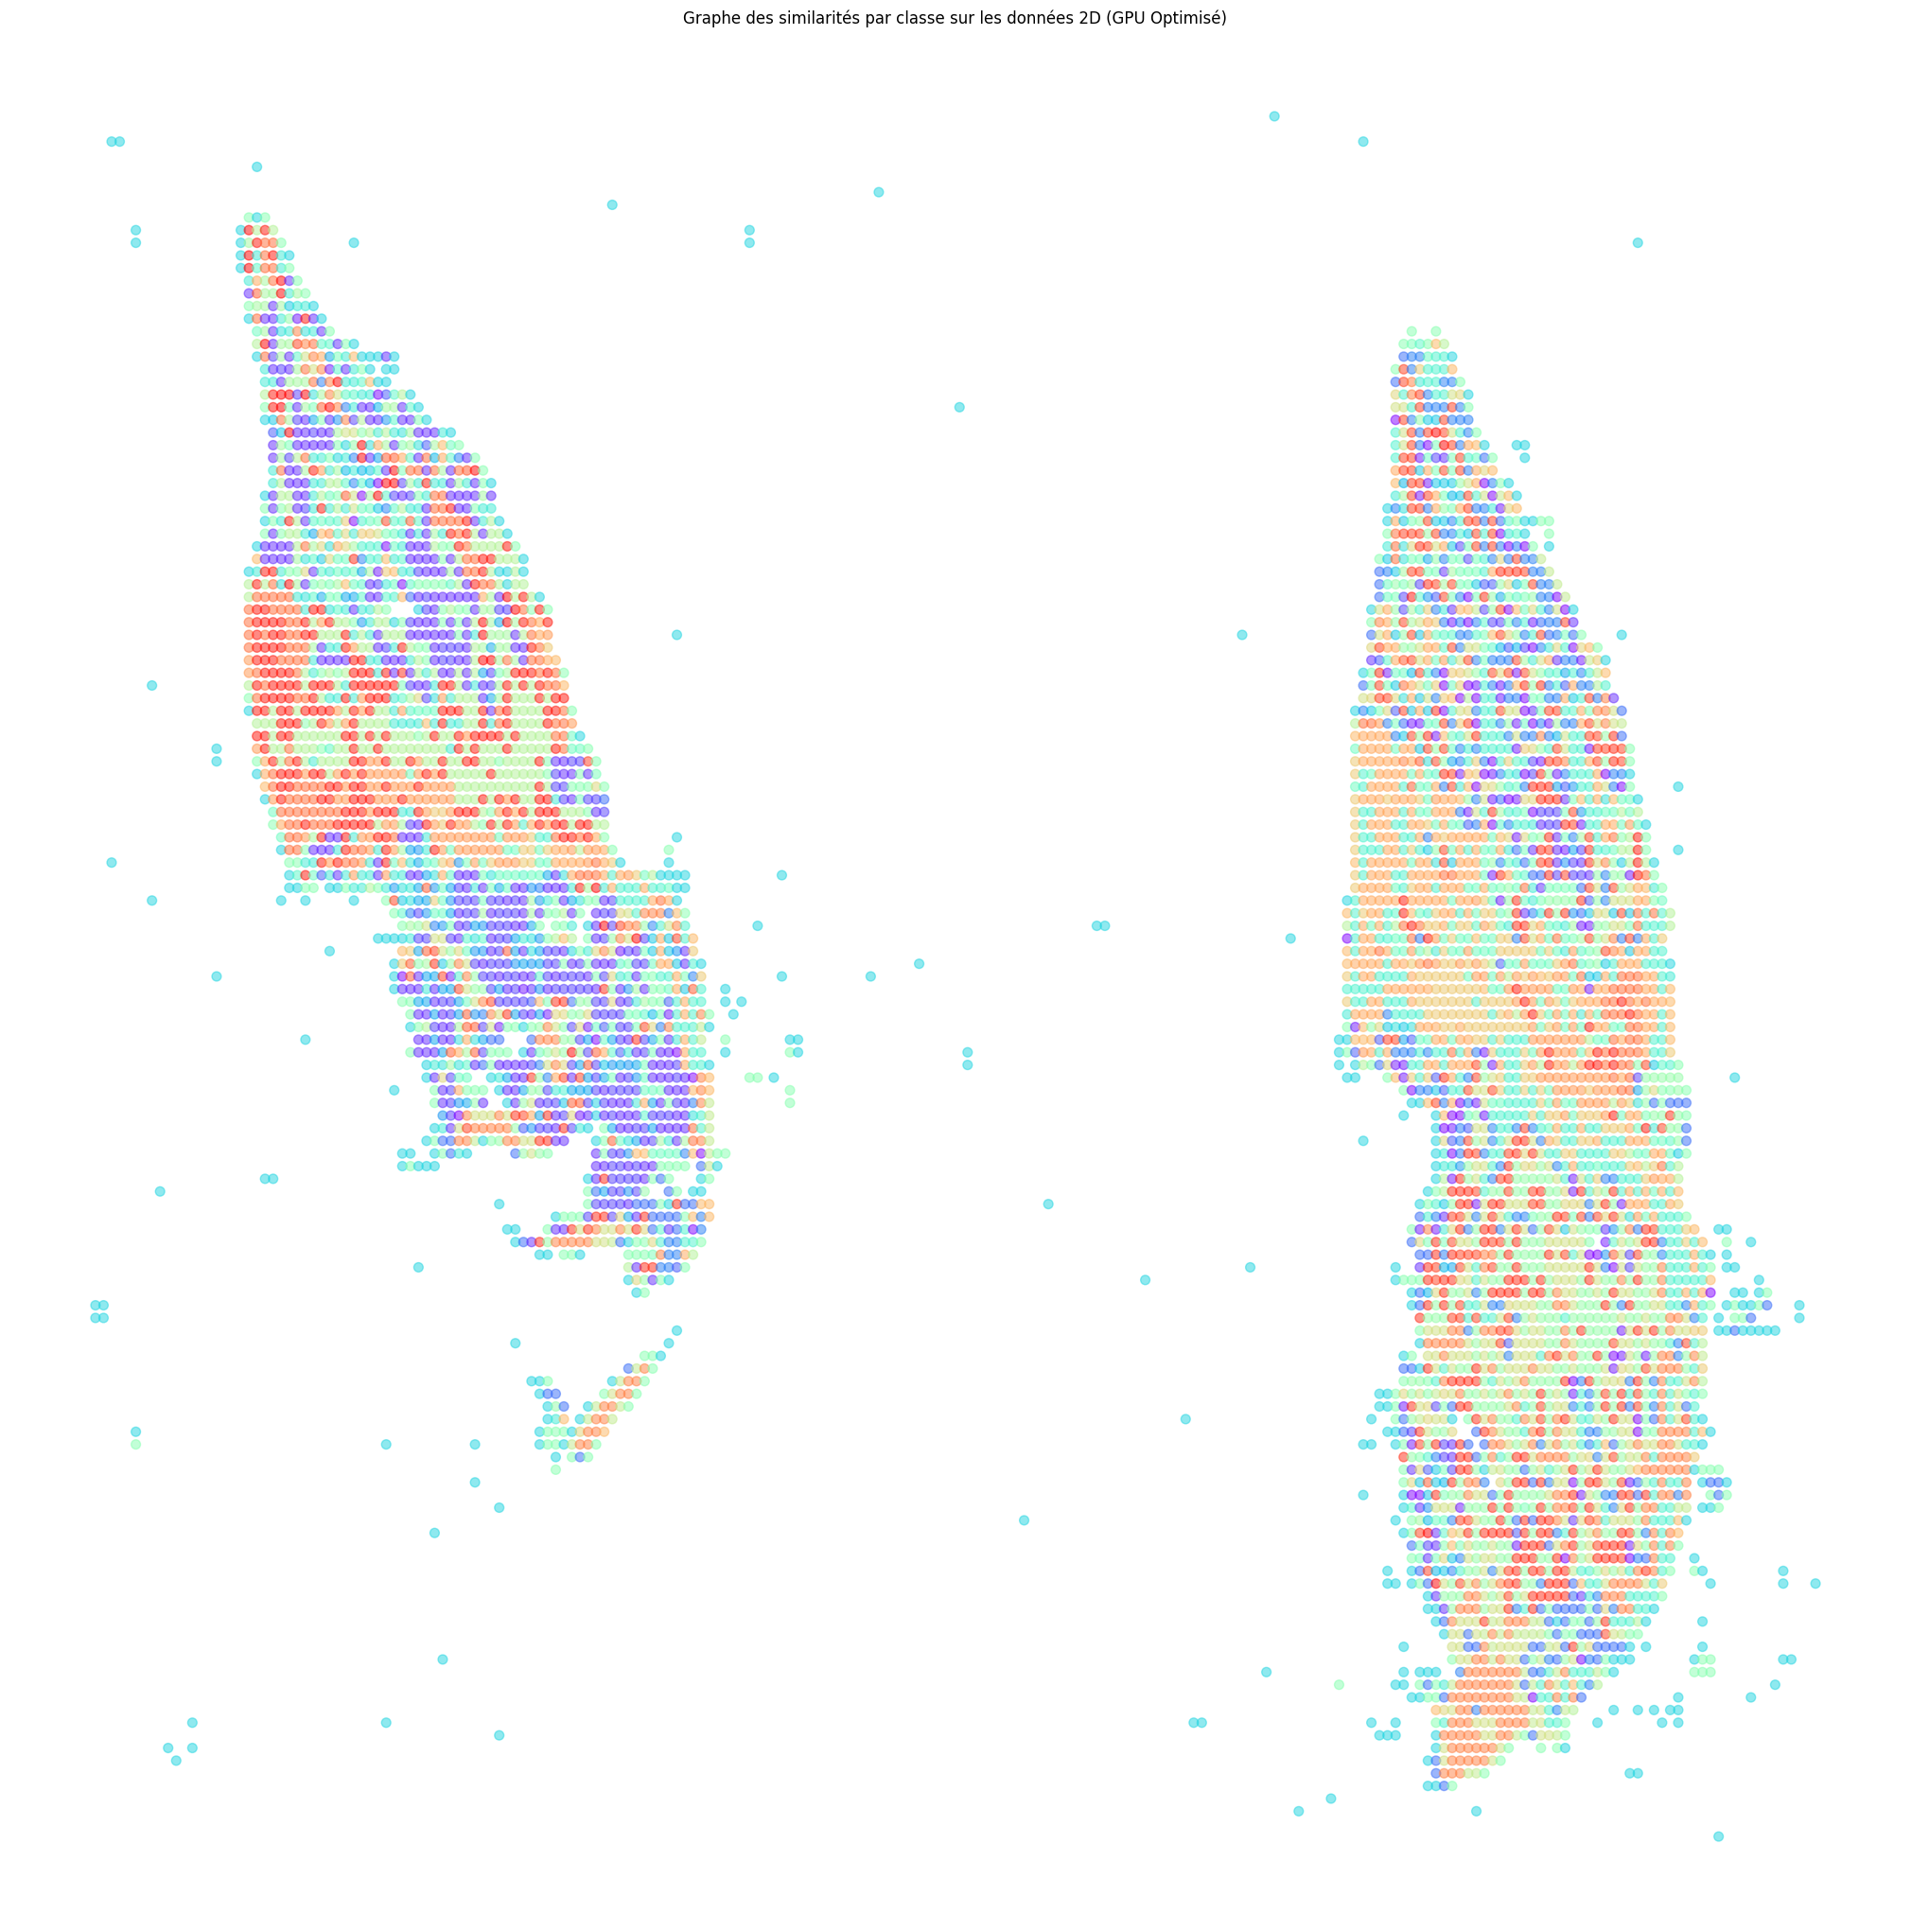

In [28]:
create_graph_gpu(pos, model_BanditPam.labels_, similarity_matrix, seuil=0.8)

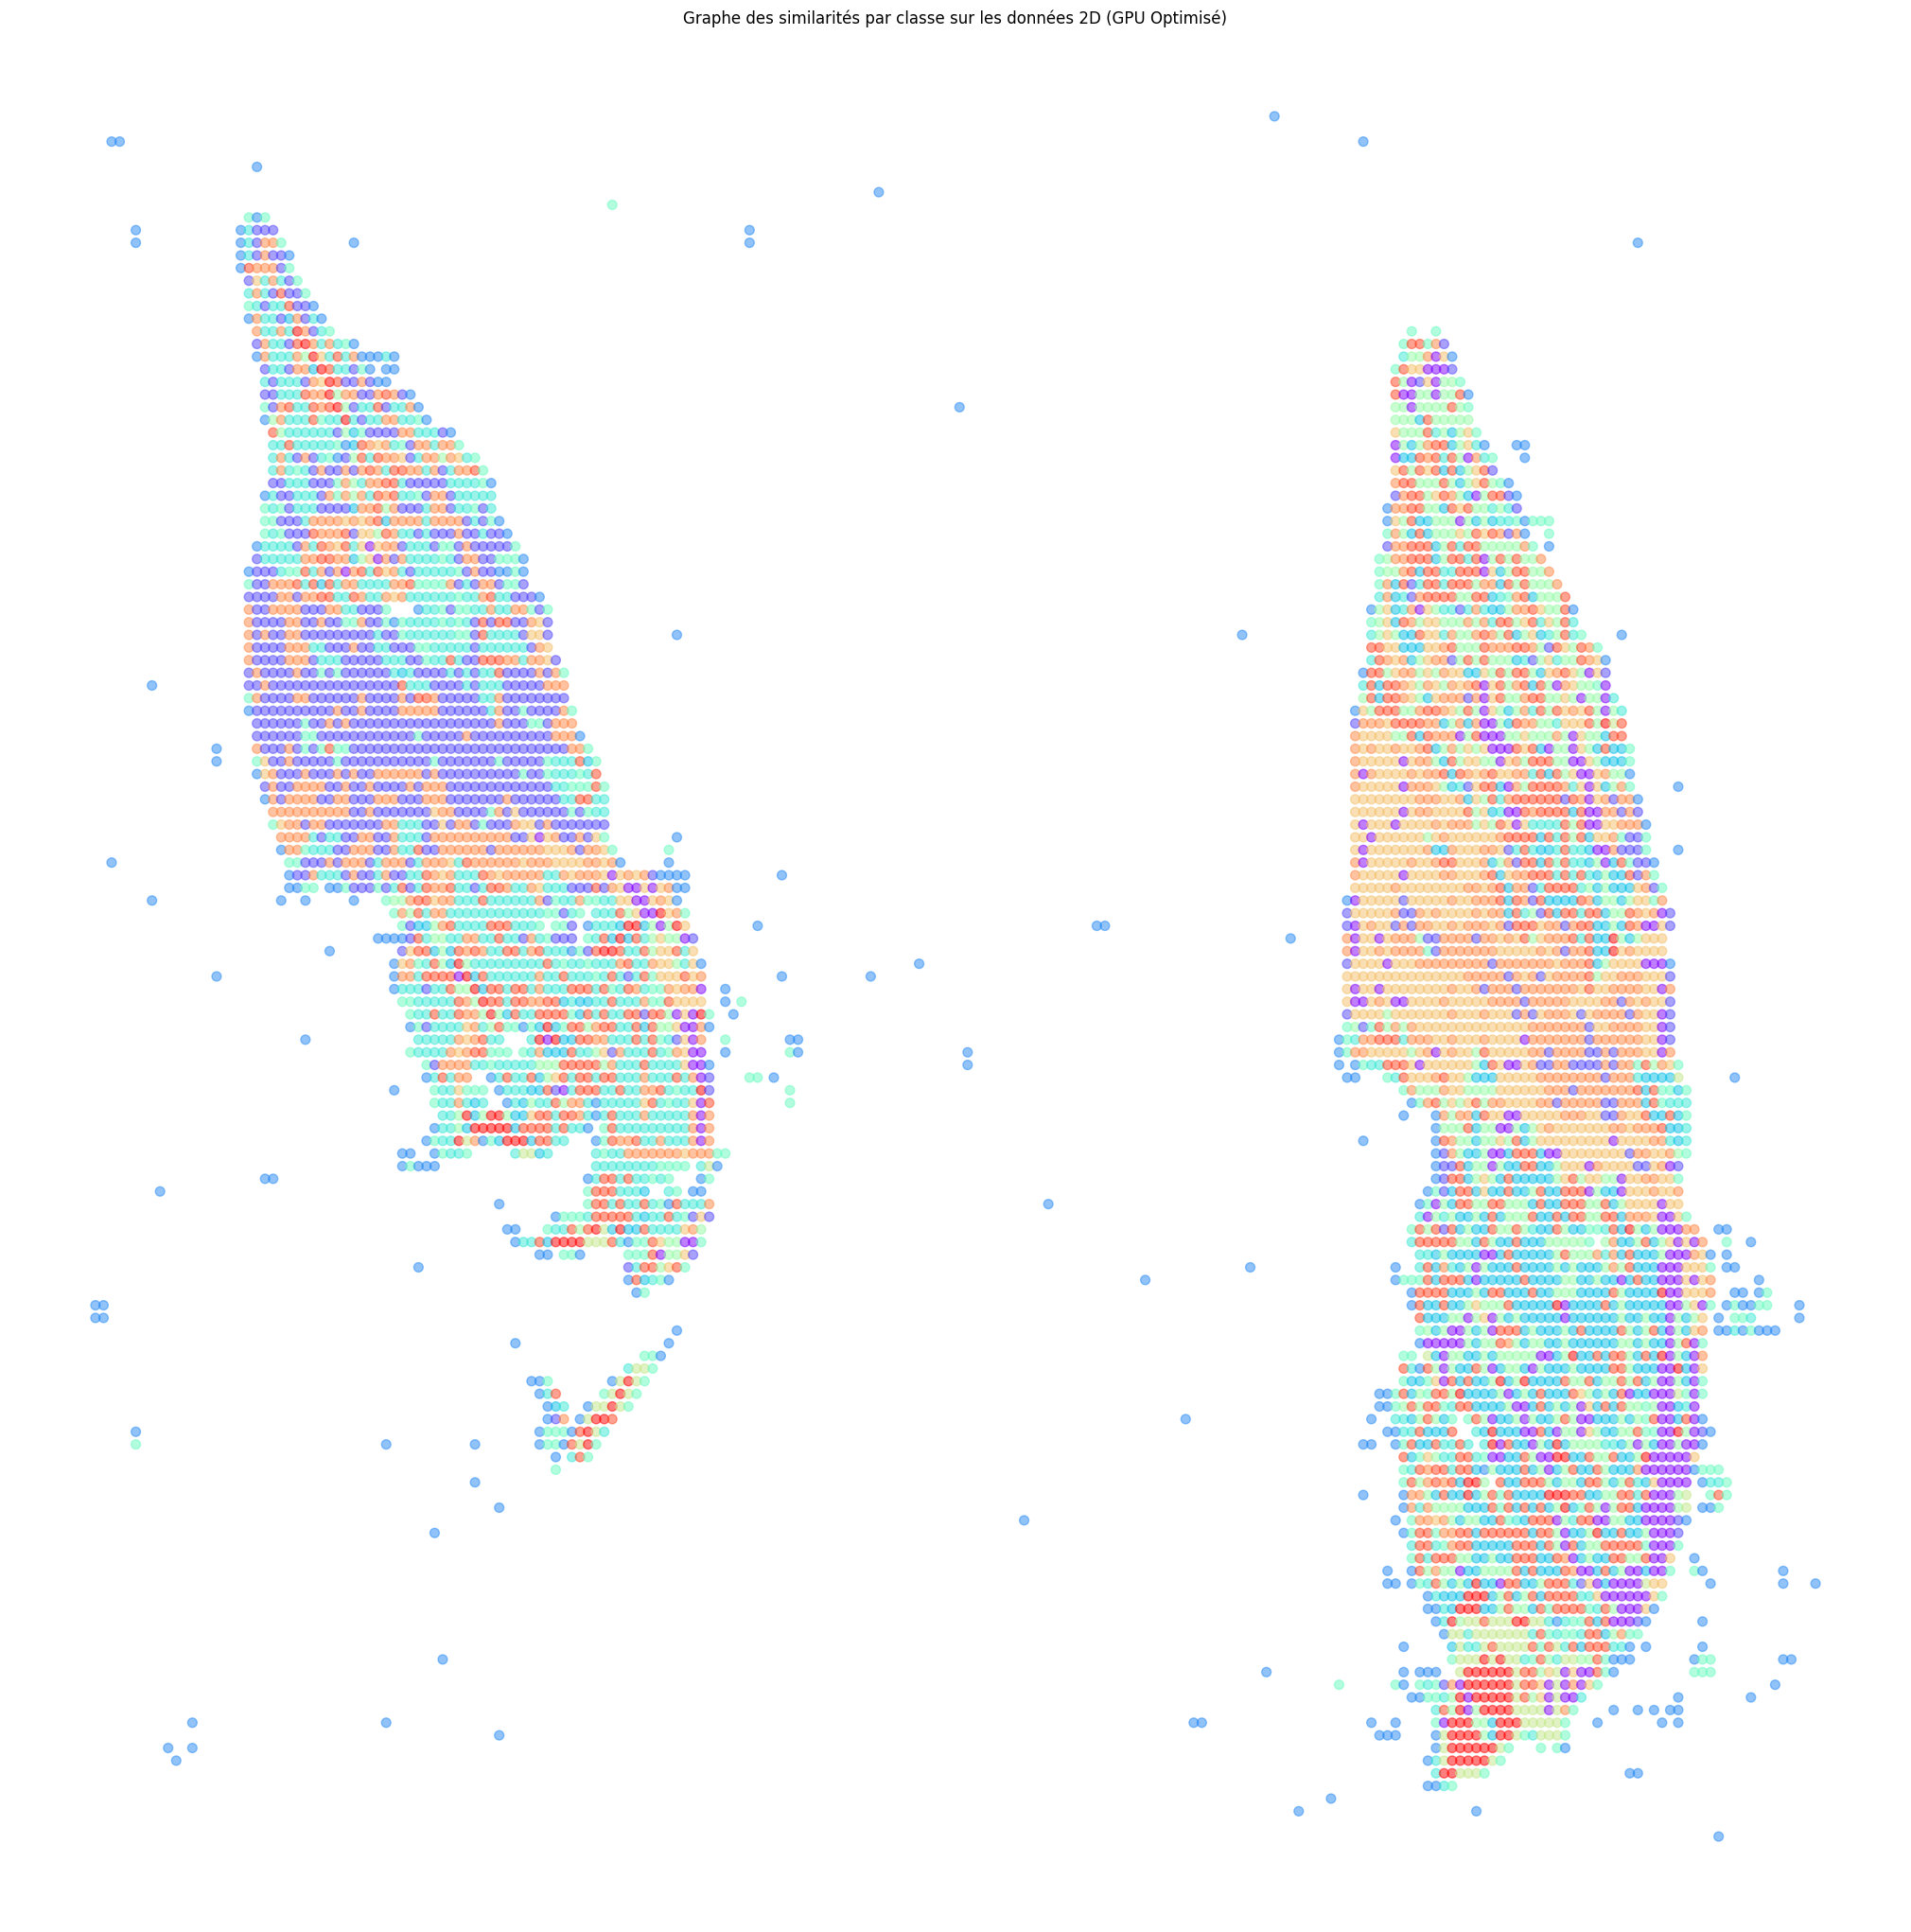

In [18]:
create_graph_gpu(pos, model_elbow.labels_, similarity_matrix, seuil=0.8)

In [ ]:
# standby -----------------------------------------------------------------------------------------------------

In [36]:
import openslide
import os
from PIL import Image
from tqdm import tqdm  # Import tqdm

def extract_patches_by_label(slide, positions, labels, output_folder):
    """
    Extrait les patches d'images d'un slide Openslide à partir de positions définies
    par les coins supérieur gauche et inférieur droit, et les enregistre dans des dossiers
    séparés par labels, avec une barre de progression tqdm.

    :param slide: Objet slide Openslide ouvert.
    :param positions: Liste de listes ou tuples [x_top_left, y_top_left, x_bottom_right, y_bottom_right]
                      représentant les coordonnées des coins de chaque patch.
    :param labels: Liste de labels correspondant à chaque patch.
    :param output_folder: Chemin du dossier de sortie principal où les dossiers de labels seront créés.
    """

    # Créer le dossier de sortie principal s'il n'existe pas
    os.makedirs(output_folder, exist_ok=True)

    # Identifier les labels uniques pour créer les dossiers correspondants
    unique_labels = set(labels)
    for label in unique_labels:
        label_folder = os.path.join(output_folder, str(label))
        os.makedirs(label_folder, exist_ok=True)

    # Utiliser tqdm pour afficher la barre de progression pendant l'extraction
    for i, position in tqdm(enumerate(positions), total=len(positions), desc="Extraction des patches"):
        label = labels[i]
        patch_filename = f"patch_{i}_label_{label}.png"
        patch_filepath = os.path.join(output_folder, str(label), patch_filename)

        # Extraire les coordonnées des coins
        x_top_left = position[0]
        y_top_left = position[1]
        x_bottom_right = position[2]
        y_bottom_right = position[3]

        # Calculer la taille du patch
        patch_width = x_bottom_right - x_top_left
        patch_height = y_bottom_right - y_top_left
        patch_size = (patch_width, patch_height)

        # Extraire le patch du slide en utilisant le coin supérieur gauche et la taille calculée
        patch = slide.read_region((x_top_left, y_top_left), 0, patch_size)

        # Convertir le patch Openslide en image PIL et enregistrer
        # patch_pil = Image.frombytes('RGBA', patch.size, patch.raw_buf, 'raw', 'RGBA', 0, 1)
        patch.save(patch_filepath)

    print(f"Extraction des patches terminée. Les patches ont été enregistrés dans : {output_folder}")
output_folder = "Patches_by_BanditPam"
os.makedirs(output_folder, exist_ok=True)
extract_patches_by_label(slide, pos, model_BanditPam.labels_, output_folder)

Extraction des patches: 100%|██████████| 6162/6162 [04:04<00:00, 25.23it/s]

Extraction des patches terminée. Les patches ont été enregistrés dans : Patches_by_BanditPam


In [33]:
import locale
def getpreferredencoding(do_setlocale = True):
    return "UTF-8"
locale.getpreferredencoding = getpreferredencoding

import locale
locale.setlocale(locale.LC_ALL, 'en_US.UTF-8')

import os
os.environ['LANG'] = 'en_US.UTF-8'
os.environ['LC_ALL'] = 'en_US.UTF-8'

print("Locale settings updated to UTF-8.")

Locale settings updated to UTF-8.


In [34]:
!zip -r Patches_by_labels_elbow.zip /content/Patches_by_labels_elbow

Le flux de sortie a été tronqué et ne contient que les 5000 dernières lignes.
  adding: content/Patches_by_labels_elbow/3/patch_5314_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_4719_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_4778_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_5180_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_5841_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_2393_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_5219_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_4623_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_4921_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_5604_label_3.png (deflated 0%)
  adding: content/Patches_by_labels_elbow/3/patch_5126_label_3.png (deflated 0%)
  adding: content/Patches_by_la

In [37]:
!cp -r /content/Patches_by_BanditPam /content/drive/MyDrive/Perso/SLA/Asclepios

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import pairwise_distances_argmin_min
import cuml
import cupy as cp  # Use CuPy for GPU-accelerated matrix operations

# Fonction pour détecter automatiquement le "coude"
def find_optimal_k(scores, method='elbow'):
    if method == 'elbow':
        diffs = np.diff(scores)
        second_diffs = np.diff(diffs)
        third_diffs = np.diff(second_diffs)
        optimal_k = np.argmax(third_diffs) + 2  # Ajouter 2 car les indices de diff sont décalés
    elif method in ["silhouette", "calinski_harabasz", "BanditPam"]:
        optimal_k = np.argmax(scores) + 2  # Ajouter 2 car l'index commence à 2
    elif method in ["davies_bouldin", "bic"]:
        optimal_k = np.argmin(scores) + 2  # Ajouter 2 car l'index commence à 2
    return optimal_k

def evaluate_clusters(X, k_range=range(2, 10), method="elbow", title="Évaluation des clusters"):
    """Évalue différentes métriques pour déterminer le nombre optimal de clusters."""
    scores = []

    # Convertir les données X en format CuPy pour GPU (si nécessaire)
    X_gpu = cp.asarray(X)

    for k in k_range:
        if method == "elbow":  # Méthode du coude
            model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X_gpu)
            scores.append(model.inertia_)
        elif method == "silhouette":  # Score de silhouette
            model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X_gpu)
            labels = model.labels_
            scores.append(silhouette_score(X, labels))
        elif method == "davies_bouldin":  # Indice de Davies-Bouldin
            model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X_gpu)
            labels = model.labels_
            scores.append(davies_bouldin_score(X, labels))
        elif method == "calinski_harabasz":  # Indice de Calinski-Harabasz
            model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X_gpu)
            labels = model.labels_
            scores.append(calinski_harabasz_score(X, labels))
        elif method == "bic":  # BIC avec GMM
            model = GaussianMixture(n_components=k, random_state=42).fit(X)
            scores.append(model.bic(X))
        elif method == "BanditPam":
            model = KMedoids(n_clusters=k, random_state=0).fit(X)
            scores.append(-model.inertia_)
        else:
            raise ValueError("Méthode inconnue. Choisissez parmi : 'elbow', 'silhouette', 'davies_bouldin', 'calinski_harabasz', 'bic'.")

    # Détermination du k optimal en fonction de la métrique
    optimal_k = find_optimal_k(scores, method=method)  # Détection du "coude" (changement de pente)

    print(f"optimal_k: {optimal_k}")

    # Affichage du graphique
    plt.plot(k_range, scores, marker="o")
    plt.scatter(optimal_k, scores[k_range.index(optimal_k)], color='red', s=100, zorder=3)
    plt.axvline(optimal_k, color='r', linestyle='--', label='Vertical Line at optimal k')
    plt.xlabel("Nombre de clusters (k)")
    plt.ylabel(method.replace("_", " ").title())  # Formatage du label
    plt.title(title)
    plt.show()

    return optimal_k

def apply_clustering(X, k, method):
    if method == "BanditPam":
        model = KMedoids(n_clusters=k, random_state=0).fit(X)
    else:
        model = cuml.cluster.KMeans(n_clusters=k, random_state=42).fit(X)
    return model

ModuleNotFoundError: No module named 'cuml'

In [ ]:
model_elbow, optimal_k_elbow = evaluate_clusters(embedding_normalized, k_range=range(2, 40, 1), method="elbow", title="Méthode du coude")
model_silhouette, optimal_k_silhouette = evaluate_clusters(embedding_normalized, k_range=range(2, 40, 1), method="silhouette", title="Indice de silhouette")
model_davies, optimal_k_davies = evaluate_clusters(embedding_normalized, k_range=range(2, 40, 1), method="davies_bouldin", title="Indice de Davies-Bouldin")
model_BanditPam, optimal_k_BanditPam = evaluate_clusters(embedding_normalized, k_range=range(2, 40, 1), method="BanditPam", title="Indice de BanditPam")

model_elbow_s, optimal_k_elbow_s = evaluate_clusters(embedding_normalized_spatial, k_range=range(2, 40, 1), method="elbow", title="Méthode du coude")
model_silhouette_s, optimal_k_silhouette_s = evaluate_clusters(embedding_normalized_spatial, k_range=range(2, 40, 1), method="silhouette", title="Indice de silhouette")
model_davies_s, optimal_k_davies_s = evaluate_clusters(embedding_normalized_spatial, k_range=range(2, 40, 1), method="davies_bouldin", title="Indice de Davies-Bouldin")
model_BanditPam_s, optimal_k_BanditPam_s = evaluate_clusters(embedding_normalized_spatial, k_range=range(2, 40, 1), method="BanditPam", title="Indice de BanditPam")

In [ ]:
print(optimal_k_elbow, optimal_k_silhouette, optimal_k_davies, optimal_k_BanditPam)
print(optimal_k_elbow_s, optimal_k_silhouette_s, optimal_k_davies_s, optimal_k_BanditPam_s)

In [ ]:
display_embedding(embedding_normalized, model_elbow, title="Visualisation des embeddings")
display_embedding(embedding_normalized, model_silhouette, title="Visualisation des embeddings")
display_embedding(embedding_normalized, model_davies, title="Visualisation des embeddings")
display_embedding(embedding_normalized, model_BanditPam, title="Visualisation des embeddings")

display_embedding(embedding_normalized_spatial, model_elbow_s, title="Visualisation des embeddings")
display_embedding(embedding_normalized_spatial, model_silhouette_s, title="Visualisation des embeddings")
display_embedding(embedding_normalized_spatial, model_davies_s, title="Visualisation des embeddings")
display_embedding(embedding_normalized_spatial, model_BanditPam_s, title="Visualisation des embeddings")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import pairwise_distances_argmin_min

# Fonction pour appliquer le clustering PAM (K-Medoids)
def bandit_pam(X, k_values):
    best_k = None
    best_score = -np.inf

    for k in k_values:
        kmedoids = KMedoids(n_clusters=k, random_state=0)
        kmedoids.fit(X)

        # Score basé sur la qualité du clustering (par exemple, la somme des distances intra-cluster)
        score = -kmedoids.inertia_  # L'inertie de KMedoids est un bon critère pour optimiser

        if score > best_score:
            best_score = score
            best_k = k

    return best_k

# Essayer différents nombres de clusters k
k_values = range(2, 40, 1)
optimal_k = bandit_pam(embedding_normalized, k_values)

print(f"Le nombre optimal de clusters (k) selon Bandit PAM est : {optimal_k}")

# Appliquer KMedoids avec k optimal trouvé
kmedoids = KMedoids(n_clusters=optimal_k, random_state=0)
kmedoids.fit(embedding_normalized)

# Visualiser les résultats
plt.scatter(embedding_normalized[:, 0], embedding_normalized[:, 1], c=kmedoids.labels_, cmap='viridis')
plt.scatter(kmedoids.cluster_centers_[:, 0], kmedoids.cluster_centers_[:, 1], s=200, c='red', marker='X')
plt.title(f"KMedoids avec k={optimal_k}")
plt.show()


In [ ]:
# from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
# from sklearn.metrics import silhouette_score, davies_bouldin_score
# from sklearn.preprocessing import StandardScaler
# from sklearn.mixture import GaussianMixture

# # Charger et standardiser les données (comme dans mon message précédent)
# scaler = StandardScaler()
# features_scaled = scaler.fit_transform(features)

# # Définir les méthodes de clustering à tester
# methods = {
#     'KMeans': (KMeans(), {'n_clusters': [10,20,30,40]}),  # Tester k de 2 à 10
#     'AgglomerativeClustering': (AgglomerativeClustering(), {'n_clusters': range(2, 11)}),
#     'DBSCAN': (DBSCAN(), {'eps': [0.1, 0.5, 1], 'min_samples': [5, 10, 20]}),  # Ajuster les valeurs pour DBSCAN
#     'GaussianMixture': (GaussianMixture(), {'n_components': range(2, 11)})
# }

# # Définir les métriques d'évaluation
# metrics = {
#     'Silhouette': silhouette_score,
#     'Davies-Bouldin': davies_bouldin_score
# }

In [ ]:
# from sklearn.model_selection import ParameterGrid

# best_score = -1  # Initialiser le meilleur score
# best_params = {}  # Initialiser les meilleurs paramètres
# best_method = ''  # Initialiser la meilleure méthode

# for method_name, (model, param_grid) in methods.items():
#     for params in ParameterGrid(param_grid):
#         # Instancier le modèle avec les paramètres courants
#         current_model = model.set_params(**params)

#         # Entraîner le modèle et obtenir les labels
#         if method_name == 'DBSCAN': # DBSCAN ne nécessite pas de n_clusters
#             labels = current_model.fit_predict(features_scaled)
#         else:
#             labels = current_model.fit_predict(features_scaled)

#         # Calculer les métriques d'évaluation
#         scores = {}
#         for metric_name, metric_func in metrics.items():
#           # Gérer le cas où le nombre de clusters est égal à 1 pour éviter une erreur avec silhouette_score
#           if len(set(labels)) > 1:
#             scores[metric_name] = metric_func(features_scaled, labels)
#           else:
#             scores[metric_name] = -1 # attribuer un mauvais score si un seul cluster a été trouvé

#         # Choisir la métrique à maximiser (ici, Silhouette)
#         score = scores['Silhouette']

#         # Mettre à jour le meilleur score et les paramètres si nécessaire
#         if score > best_score:
#             best_score = score
#             best_params = params
#             best_method = method_name

# print("Meilleure méthode :", best_method)
# print("Meilleurs paramètres :", best_params)
# print("Meilleur score (Silhouette) :", best_score)

# # Visualisation (avec la meilleure méthode et les meilleurs paramètres)
# best_model = methods[best_method][0].set_params(**best_params)
# if best_method == 'DBSCAN': # DBSCAN ne nécessite pas de n_clusters
#     best_labels = best_model.fit_predict(features_scaled)
# else:
#     best_labels = best_model.fit_predict(features_scaled)

# pca = PCA(n_components=2)
# features_reduced = pca.fit_transform(features_scaled)
# plt.scatter(features_reduced[:, 0], features_reduced[:, 1], c=best_labels, cmap='viridis')
# plt.title(f'Clustering avec {best_method} (Silhouette = {best_score:.2f})')
# plt.show()

Meilleur parametrage:

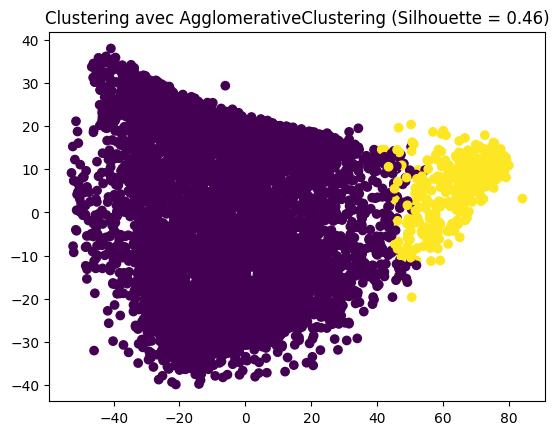

In [ ]:
# import numpy as np
# from sklearn.cluster import AgglomerativeClustering
# from sklearn.metrics import silhouette_score, davies_bouldin_score
# from sklearn.preprocessing import StandardScaler
# from sklearn.model_selection import ParameterGrid
# import matplotlib.pyplot as plt
# from sklearn.decomposition import PCA

# # Charger et standardiser les données
# scaler = StandardScaler()
# features_scaled = scaler.fit_transform(features)

# # Définir les paramètres à tester
# param_grid = {
#     'n_clusters': [3,4,5,10,11,12],  # Nombre de clusters à tester
#     'linkage': ['ward', 'complete', 'average', 'single'],  # Méthodes de linkage à tester
# }

# # Définir les métriques d'évaluation
# metrics = {
#     'Silhouette': silhouette_score,
#     'Davies-Bouldin': davies_bouldin_score
# }

# best_score = -1
# best_params = {}

# # Itérer sur toutes les combinaisons de paramètres
# for params in ParameterGrid(param_grid):
#     # Créer le modèle avec les paramètres courants
#     model = AgglomerativeClustering(**params)

#     # Entraîner le modèle et obtenir les labels de cluster
#     labels = model.fit_predict(features_scaled)

#      # Calculer les métriques d'évaluation
#     scores = {}
#     for metric_name, metric_func in metrics.items():
#       # Gérer le cas où le nombre de clusters est égal à 1 pour éviter une erreur avec silhouette_score
#       if len(set(labels)) > 1:
#         scores[metric_name] = metric_func(features_scaled, labels)
#       else:
#         scores[metric_name] = -1 # attribuer un mauvais score si un seul cluster a été trouvé

#     # Choisir la métrique à maximiser (ici, Silhouette)
#     score = scores['Silhouette']

#     # Mettre à jour le meilleur score et les paramètres si nécessaire
#     if score > best_score:
#         best_score = score
#         best_params = params

# print("Meilleurs paramètres :", best_params)
# print("Meilleur score (Silhouette) :", best_score)

# # Visualisation des résultats avec les meilleurs paramètres
# best_model = AgglomerativeClustering(**best_params)
# best_labels = best_model.fit_predict(features_scaled)

# pca = PCA(n_components=2)
# features_reduced = pca.fit_transform(features_scaled)
# plt.scatter(features_reduced[:, 0], features_reduced[:, 1], c=best_labels, cmap='viridis')
# plt.title(f'Clustering avec AgglomerativeClustering (Silhouette = {best_score:.2f})')
# plt.show()

In [ ]:
scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

# Sélectionner les 3 features (remplacez 0, 1, 2 par les indices des features)
x = features_scaled[:, 0]
y = features_scaled[:, 1]
z = features_scaled[:, 2]

# Créer la figure 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

# Afficher les points
scatter = ax.scatter(x, y, z)

# Ajouter des labels et un titre
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.set_zlabel('Feature 3')
plt.title('Données en 3D')

# Afficher le graphique
plt.show()

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
similarity_matrix = cosine_similarity(features)
similarity_matrix_scaled = scaler.fit_transform(features)

In [ ]:
import seaborn as sns
sns.heatmap(similarity_matrix_scaled, cmap='viridis', annot=False, fmt=".2f") # Ajout des valeurs dans les cases
plt.title('Matrice de similarité')
plt.show()

In [ ]:
from sklearn.cluster import AffinityPropagation

seuil = 0.9 # Ajustez ce seuil en fonction de vos données et de vos objectifs

# Créer la matrice d'adjacence
adjacency_matrix = (similarity_matrix_scaled > seuil).astype(float)

# Utiliser Affinity Propagation pour le clustering
af = AffinityPropagation(affinity='euclidean').fit(adjacency_matrix)
labels = af.labels_

In [ ]:
labels

In [ ]:
# Visualiser les résultats (en utilisant les coordonnées 2D si disponibles)
try:
    # Charger les coordonnées 2D (remplacez par le chemin vers votre fichier)
    coordinates_2d = np.load('/content/drive/MyDrive/Perso/SLA/Asclepios/wsi_features/0.position.npy')

    plt.figure(figsize=(20, 20))
    plt.scatter(coordinates_2d[:, 0], coordinates_2d[:, 1], c=labels, cmap='viridis')
    plt.title("Clustering basé sur la similarité (Affinity Propagation)")
    plt.xlabel("Dimension 1")  # Remplacez par le nom de votre dimension
    plt.ylabel("Dimension 2")  # Remplacez par le nom de votre dimension
    plt.show()

except FileNotFoundError:
    print("Fichier de coordonnées 2D non trouvé. La visualisation ne peut pas être affichée.")

In [ ]:
import seaborn as sns
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
feature_scaled = scaler.fit_transform(features)
similarity_matrix_scaled = euclidean_distances(feature_scaled)
seuil = 0.9 # Ajustez ce seuil en fonction de vos données et de vos objectifs
adjacency_matrix = (feature_scaled > seuil).astype(float)
sns.heatmap(similarity_matrix_scaled, cmap='viridis', annot=False, fmt=".2f") # Ajout des valeurs dans les cases
plt.title('Matrice de similarité')

plt.show()

In [ ]:
import networkx as nx
# Créer le graphe
def create_graph(matrix,coordinates_2d, features,  seuil = 0.9, ):
    graph = nx.Graph()

    # Ajouter les nœuds avec leurs positions 2D
    for i in range(len(features)):
        x_start = coordinates_2d[i, 0]  # Coordonnée x du point de départ
        y_start = coordinates_2d[i, 1]  # Coordonnée y du point de départ
        graph.add_node(i, pos=(x_start, y_start))

    # Ajouter les arêtes entre les nœuds similaires
    for i in range(len(features)):
        for j in range(i + 1, len(features)):  # Pour éviter les doublons et les boucles
            if matrix[i, j] > seuil:
                graph.add_edge(i, j, weight=matrix[i, j])

    # Visualiser le graphe sur le scatter plot existant
    plt.figure(figsize=(20, 20))
    plt.scatter(coordinates_2d[:, 0], coordinates_2d[:, 1])  # Afficher les points (sans les couleurs des clusters)

    # Dessiner le graphe sur le scatter plot
    nx.draw(graph, pos=nx.get_node_attributes(graph, 'pos'),
            with_labels=False, node_size=10, node_color='red',
            edge_color='gray', alpha=0.5, width=0.5)

    plt.title("Graphe des similarités sur les données 2D")
    plt.xlabel("Composante principale 1")
    plt.ylabel("Composante principale 2")
    plt.show()

In [ ]:
coordinates_2d = np.load('/content/drive/MyDrive/Perso/SLA/Asclepios/wsi_features/0.position.npy')

create_graph(similarity_matrix_scaled, coordinates_2d, features, seuil = 22)